# 第13章 直方图处理（跟随代码）

> 《OpenCV轻松入门：面向Python》第 13 章的跟随代码，内容未做改动。
> 运行前请确认工作目录为本文件夹（picture*.jpg 等素材都在这里）。

# 第十三章 直方图处理

## 绘制直方图


(array([  1932.,   6970.,  29668.,  78434.,  90983.,  77809.,  68881.,
         67422.,  70548.,  89230., 148527., 164750., 153664., 207246.,
        261242., 556294.]),
 array([  0.    ,  15.9375,  31.875 ,  47.8125,  63.75  ,  79.6875,
         95.625 , 111.5625, 127.5   , 143.4375, 159.375 , 175.3125,
        191.25  , 207.1875, 223.125 , 239.0625, 255.    ]),
 <BarContainer object of 16 artists>)

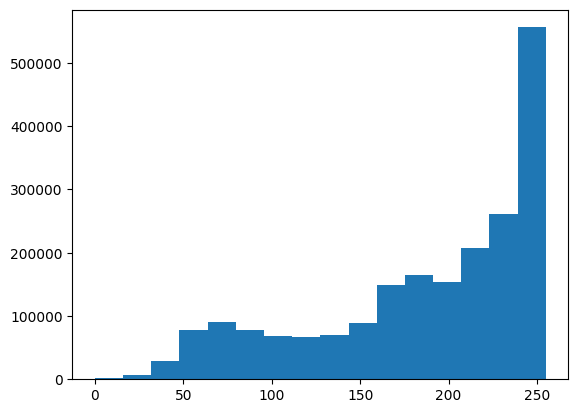

In [253]:
# 使用Numpy绘制直方图

import cv2
import matplotlib.pyplot as plt

img=cv2.imread("picture1.jpg")

img=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)

plt.hist(img.ravel(),16)

[[18428.]
 [ 2775.]
 [ 3347.]
 [ 2902.]
 [ 3249.]
 [ 3464.]
 [ 3118.]
 [ 3703.]
 [ 3407.]
 [ 3818.]
 [ 3505.]
 [ 4128.]
 [ 4079.]
 [ 3591.]
 [ 4357.]
 [ 4346.]
 [ 5713.]
 [ 5598.]
 [ 6136.]
 [ 5792.]
 [ 5978.]
 [ 5681.]
 [ 6266.]
 [ 9183.]
 [ 8844.]
 [11488.]
 [10153.]
 [12733.]
 [12347.]
 [14761.]
 [15324.]
 [16856.]
 [15823.]
 [15780.]
 [18169.]
 [16181.]
 [15202.]
 [13006.]
 [10998.]
 [12524.]
 [12204.]
 [11710.]
 [10882.]
 [13550.]
 [12139.]
 [13005.]
 [14807.]
 [11681.]
 [14389.]
 [11403.]
 [11007.]
 [ 8883.]
 [ 7648.]
 [ 7478.]
 [ 7401.]
 [ 7550.]
 [ 7038.]
 [ 7191.]
 [ 7715.]
 [ 7756.]
 [ 8629.]
 [ 8421.]
 [ 9584.]
 [ 8941.]
 [ 8846.]
 [ 9849.]
 [ 9268.]
 [10898.]
 [ 9027.]
 [ 9605.]
 [ 8117.]
 [ 8911.]
 [10810.]
 [ 9974.]
 [11449.]
 [10038.]
 [13507.]
 [ 9109.]
 [11503.]
 [ 8595.]
 [ 9912.]
 [10281.]
 [ 9084.]
 [ 8344.]
 [ 8141.]
 [ 7745.]
 [ 8043.]
 [ 8366.]
 [ 8083.]
 [ 8912.]
 [ 7728.]
 [ 7962.]
 [ 6890.]
 [ 7162.]
 [ 5654.]
 [ 5965.]
 [ 5432.]
 [ 5886.]
 [ 5568.]
 [ 5211.]


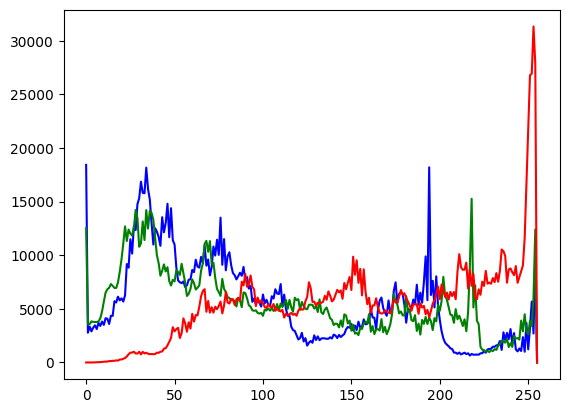

In [254]:
# 使用OpenCV绘制直方图

img=cv2.imread("picture2.png")

histb=cv2.calcHist([img],[0],None,[256],[0,255])
histg=cv2.calcHist([img],[1],None,[256],[0,255])
histr=cv2.calcHist([img],[2],None,[256],[0,255])

print(histb)

plt.plot(histb,color='b')
plt.plot(histg,color='g')
plt.plot(histr,color='r')
plt.show()

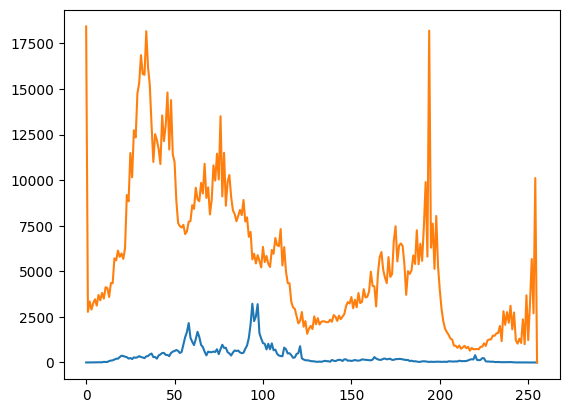

In [255]:
#使用掩膜绘制直方图

img=cv2.imread("picture2.png")
img=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
mask=np.zeros(img.shape,np.uint8)

for i in range(200,500):
    for j in range(200,500):
        mask[i][j]=255

cv_show("mask",mask)


hist1=cv2.calcHist([img],[0],mask,[256],[0,256])

plt.plot(hist1)
plt.plot(histb)
plt.show()

## 直方图均衡化

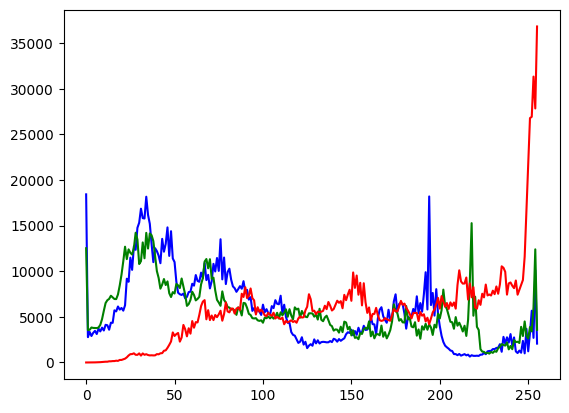

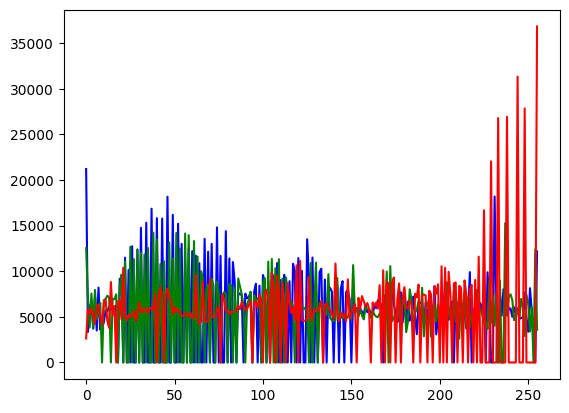

In [256]:
img=cv2.imread("picture2.png")

b,g,r=cv2.split(img)
equb=cv2.equalizeHist(b)
equg=cv2.equalizeHist(g)
equir=cv2.equalizeHist(r)

equ=cv2.merge([equb,equg,equir])

cv_show("equalized",equ)
cv_show("original",img)

plt.figure("原始图像直方图:")
histb=cv2.calcHist([b],[0],None,[256],[0,256])
histg=cv2.calcHist([g],[0],None,[256],[0,256])
histr=cv2.calcHist([r],[0],None,[256],[0,256])
plt.plot(histb,color='b')
plt.plot(histg,color='g')
plt.plot(histr,color='r')

plt.figure("均衡化后图像直方图:")
equhistb=cv2.calcHist([equb],[0],None,[256],[0,256])
equhistg=cv2.calcHist([equg],[0],None,[256],[0,256])
equhistr=cv2.calcHist([equir],[0],None,[256],[0,256])
plt.plot(equhistb,color='b')
plt.plot(equhistg,color='g')
plt.plot(equhistr,color='r')

plt.show()

## pyplot模块

- subplot()函数：创建子图
- imshow()函数：显示图像

C:\Users\17272\AppData\Local\Temp\ipykernel_43968\3963227393.py:1: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.subplot(121),plt.hist(img.ravel(),256,[0,256])
C:\Users\17272\AppData\Local\Temp\ipykernel_43968\3963227393.py:2: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.subplot(122),plt.hist(equ.ravel(),256,[0,256])


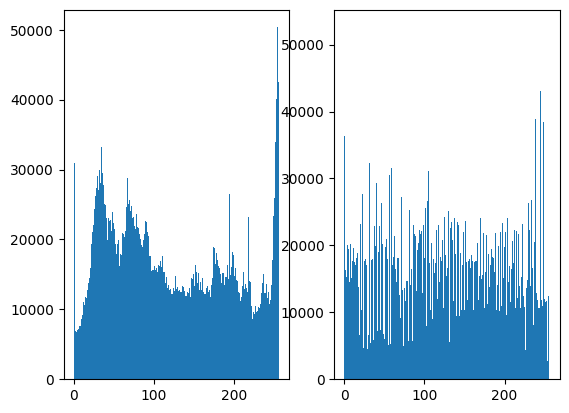

In [257]:
plt.subplot(121),plt.hist(img.ravel(),256,[0,256])
plt.subplot(122),plt.hist(equ.ravel(),256,[0,256])
plt.show()

(<Axes: >, <matplotlib.image.AxesImage at 0x2c910ab0820>)

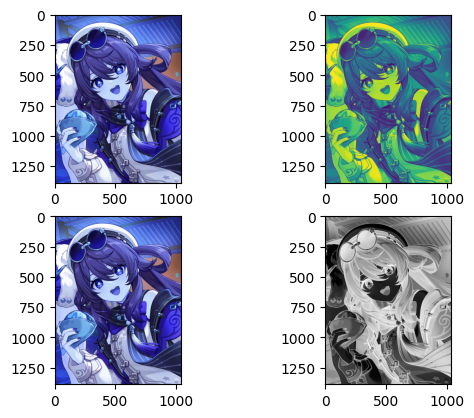

In [258]:
gray=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)


plt.subplot(221),plt.imshow(img)
plt.subplot(222),plt.imshow(gray)
plt.subplot(223),plt.imshow(img,plt.cm.gray_r)
plt.subplot(224),plt.imshow(gray,plt.cm.gray_r)